# 02 — Preparación y validación de datos

En este cuaderno ejecutamos la preparación de src/data: filtramos etiquetas supervisadas, estimamos tamaño relativo, hacemos particiones reproducibles, procesamos imágenes a 128 × 128 y generamos vectores de 108 características. Después creamos recortes candidatos de las escenas Mixed, conservando el grupo de origen y sin asignarles calidad.

La fuente disponible contiene Good y Bad; no hay ejemplos Regular ni fotos propias. Mostramos esa ausencia explícitamente. El reinicio del directorio procesado conserva annotations.csv y los marcadores .gitkeep versionados.

In [1]:
from contextlib import redirect_stderr, redirect_stdout
from io import StringIO
from pathlib import Path
import json
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.dataset import FINAL_QUALITY_CLASSES, scan_labeled_dataset
from src.data.feature_extraction import FEATURE_DIM
from src.data.prepare_data import PROCESSED_DIR, RAW_KAGGLE, run_eda_pipeline
from src.data.segmentation import segment_mixed_dataset
from src.data.load_data import load_ml_arrays

PROCESSED_DIR = PROCESSED_DIR.resolve()
assert PROCESSED_DIR == (ROOT / "data" / "processed").resolve()
print(f"Dataset de entrada: {RAW_KAGGLE}")
print(f"Salidas procesadas: {PROCESSED_DIR}")
print(f"Marcador de anotaciones conservado: {(PROCESSED_DIR / 'annotations.csv').exists()}")

Dataset de entrada: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton\data\raw\kaggle
Salidas procesadas: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton\data\processed
Marcador de anotaciones conservado: True


In [2]:
# Reiniciamos solo las salidas derivadas; conservamos anotaciones y archivos .gitkeep.
log_buffer = StringIO()
start = time.perf_counter()
with redirect_stdout(log_buffer), redirect_stderr(log_buffer):
    run_summary = run_eda_pipeline(reset_processed=True)
elapsed_minutes = (time.perf_counter() - start) / 60
log_lines = [line.strip() for line in log_buffer.getvalue().replace("\r", "\n").splitlines() if line.strip()]
print(f"Resumen del pipeline: {run_summary}")
print(f"Duración: {elapsed_minutes:.1f} min")
print("Últimas líneas del proceso:")
print("\n".join(log_lines[-12:]))

Resumen del pipeline: {'manifest_size': 18452, 'train_size': 12916, 'val_size': 2768, 'test_size': 2768}
Duración: 45.0 min
Últimas líneas del proceso:
test/Bad: 100%|##########| 1019/1019 [00:20<00:00, 49.39it/s]
EDA/preparation completed.


In [3]:
manifest = pd.read_csv(PROCESSED_DIR / "final_manifest.csv")
splits = {name: pd.read_csv(PROCESSED_DIR / f"{name}.csv") for name in ["train", "val", "test"]}
with (PROCESSED_DIR / "labelinfo.json").open(encoding="utf-8") as file:
    label_info = json.load(file)
with (PROCESSED_DIR / "classweights.json").open(encoding="utf-8") as file:
    class_weights = json.load(file)

assert label_info["class_names"] == FINAL_QUALITY_CLASSES
assert set(manifest["quality"].unique()) == {"Good", "Bad"}
assert len(manifest) == sum(len(split) for split in splits.values())
assert all(split["processed_path"].map(lambda path: Path(path).is_file()).all() for split in splits.values())

split_counts = pd.DataFrame({name: split["quality"].value_counts() for name, split in splits.items()}).fillna(0).astype(int)
split_counts = split_counts.reindex(FINAL_QUALITY_CLASSES, fill_value=0)
split_counts.loc["Total"] = split_counts.sum(axis=0)
display(split_counts)
print(f"Manifest supervisado: {len(manifest):,} imágenes")
print(f"Mapa de clases: {label_info['label_map']}")
print(f"Pesos de las clases con datos: {class_weights}")

,train,val,test
quality,,,
Good,8165,1750,1749
Regular,0,0,0
Bad,4751,1018,1019
Total,12916,2768,2768


Manifest supervisado: 18,452 imágenes
Mapa de clases: {'Good': 0, 'Regular': 1, 'Bad': 2}
Pesos de las clases con datos: {'0': 0.7909369259032456, '2': 1.35929278046727}


In [4]:
groups = {name: set(split["group_id"].astype(str)) for name, split in splits.items()}
for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = groups[left] & groups[right]
    print(f"Grupos compartidos {left}/{right}: {len(overlap)}")
    assert not overlap, f"Fuga de grupos entre {left} y {right}"

arrays = load_ml_arrays(PROCESSED_DIR)
array_summary = []
for name in ["train", "val", "test"]:
    X, y = arrays[f"X{name}"], arrays[f"y{name}"]
    assert X.ndim == 2 and X.shape[1] == FEATURE_DIM
    assert y.ndim == 1 and len(y) == len(X)
    assert np.isfinite(X).all(), f"Hay valores no finitos en X{name}"
    expected_counts = split_counts[name].reindex(FINAL_QUALITY_CLASSES, fill_value=0).to_numpy()
    observed_counts = np.bincount(y, minlength=len(FINAL_QUALITY_CLASSES))
    assert np.array_equal(observed_counts, expected_counts), f"Desalineación de etiquetas en {name}"
    array_summary.append({"split": name, "X_shape": X.shape, "y_shape": y.shape, "counts_by_label_index": observed_counts.tolist()})
display(pd.DataFrame(array_summary))
display(manifest["size_label"].fillna("unknown").value_counts().rename("images").to_frame())

Grupos compartidos train/val: 0
Grupos compartidos train/test: 0
Grupos compartidos val/test: 0


,split,X_shape,y_shape,counts_by_label_index
0,train,"(12916, 108)","(12916,)","[8165, 0, 4751]"
1,val,"(2768, 108)","(2768,)","[1750, 0, 1018]"
2,test,"(2768, 108)","(2768,)","[1749, 0, 1019]"


,images
size_label,
large,15180
medium,1943
unknown,1188
small,141


## Escenas Mixed: recortes candidatos sin calidad asignada

Las imágenes Mixed requieren segmentación por objeto y revisión manual. Guardamos recortes y un manifiesto que conserva source_image_id y group_id; las etiquetas de calidad quedan vacías. La calidad de cada recorte se deberá acordar y anotar antes de incorporarlo al entrenamiento.

In [5]:
labeled_public, mixed_public = scan_labeled_dataset(RAW_KAGGLE, "kaggle")
MIXED_OUTPUT = PROCESSED_DIR / "images" / "mixed_candidates"
segmentation_log = StringIO()
with redirect_stdout(segmentation_log), redirect_stderr(segmentation_log):
    mixed_manifest = segment_mixed_dataset(mixed_public, MIXED_OUTPUT, reset_output=True)
manifest_path = MIXED_OUTPUT / "manifest.csv"
mixed_manifest.to_csv(manifest_path, index=False)

assert len(mixed_public) == 1_074
assert not mixed_manifest.empty
assert mixed_manifest["quality"].fillna("").eq("").all()
assert mixed_manifest["group_id"].notna().all()

crops_per_source = mixed_manifest.groupby("source_image_id").size()
print(f"Escenas Mixed de entrada: {len(mixed_public):,}")
print(f"Recortes candidatos: {len(mixed_manifest):,}")
print(f"Escenas con recorte: {crops_per_source.size:,}")
print(f"Manifiesto: {manifest_path}")
display(crops_per_source.describe().to_frame("crops_per_scene"))

Escenas Mixed de entrada: 1,074
Recortes candidatos: 1,318
Escenas con recorte: 1,074
Manifiesto: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton\data\processed\images\mixed_candidates\manifest.csv


,crops_per_scene
count,1074.000000
mean,1.227188
std,0.667838
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,6.000000


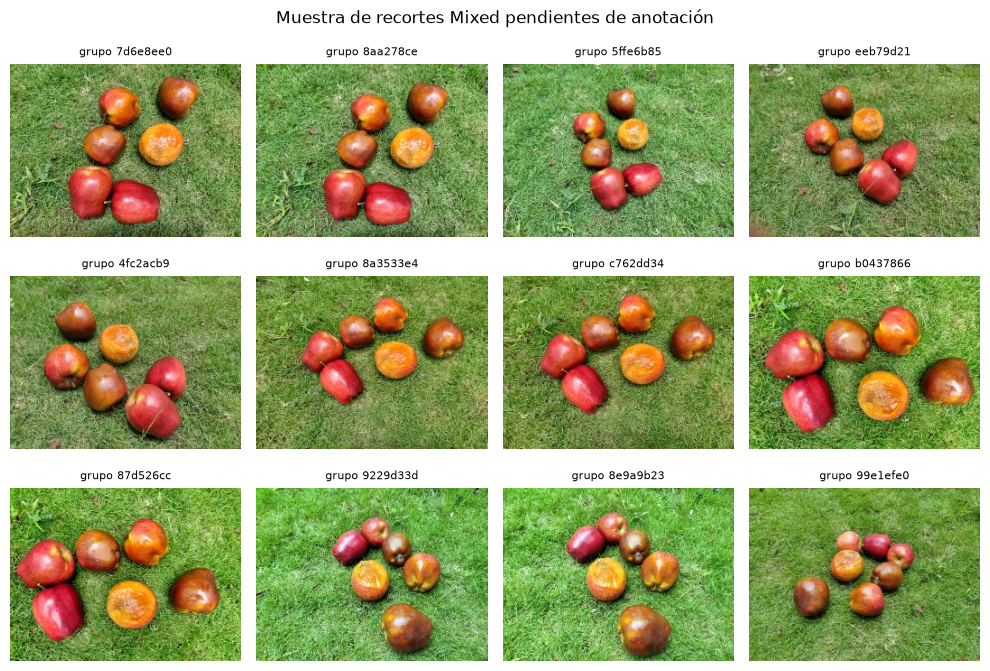

In [6]:
sample_crops = mixed_manifest.head(12)
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax, (_, row) in zip(axes.flat, sample_crops.iterrows()):
    ax.axis("off")
    image = cv2.imread(row["path"])
    if image is not None:
        h, w = image.shape[:2]
        scale = min(1.0, 320 / max(h, w))
        if scale < 1.0:
            image = cv2.resize(image, (round(w * scale), round(h * scale)))
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f"grupo {row['group_id'][-8:]}", fontsize=8)
for ax in axes.flat[len(sample_crops):]:
    ax.axis("off")
fig.suptitle("Muestra de recortes Mixed pendientes de anotación")
fig.tight_layout()
plt.show()

## Resultado de la preparación

El manifiesto y los arrays corresponden únicamente a las imágenes públicas Good y Bad. Regular queda con soporte cero mientras no se integren ejemplos propios etiquetados; Mixed conserva recortes candidatos sin calidad. Esta ejecución verifica lectura, partición, procesamiento y extracción de características, y no es una evaluación de tres clases. El tamaño producido es una estimación relativa basada en contornos; la validación con medidas físicas corresponde a la fase de evaluación.